# SOLPS-NN training data (Dasbach et al.): exploration

Reproduces the dataset analysis of *Dasbach, Brezinsek, Liang, Reiser, Wiesen,
"Deep-Learning based surrogate models for plasma exhaust simulations - SOLPS-NN"*,
[arXiv:2604.19223](https://arxiv.org/abs/2604.19223) (Section 2, Figures 1-3, and the QoIs of
Section 5), on the public data release
[SOLPS-NN Training Data v1, Zenodo 10.5281/zenodo.19237127](https://zenodo.org/records/19237127)
(CC BY 4.0). Trained SOLPS-NN weights: [github.com/sdasbach/solps-nn](https://github.com/sdasbach/solps-nn).

**What the data is.** SOLPS-ITER (B2.5 only, *fluid* neutrals, no EIRENE, no drifts, potential not
solved) on a single JET-like vertical-target grid (JET pulse 85423 shape, 102 x 48 cells) whose size
is scaled with the major radius `R` at fixed aspect ratio and q95. Eight scalar inputs are varied
(`R, B, P_in, D_puff, N_puff, D_core, D_perp, chi_perp`), 8192 training runs (Sobol) and 2048 test runs
(uniform random); about 30 % diverge and are absent. Species: D0, D+, N0, N1+ ... N7+.
This is *not* a machine-specific dataset (not SPARC): it spans AUG- to DEMO-size devices.

**Why we care.** SOLPS-NN is a fully-connected `R^8 -> R^(104x50)` MLP per observable (Table 2/3 of the
paper give the test-set medians to beat). The dataset is a cross-machine, fixed-topology benchmark for
the SOLSTICE GNN state model (`params -> fields`); the last section maps the release onto the
`solstice` canonical schema.

Reading conventions (from the release `example.py` and `solpsnn/geometry.py`):
arrays are `(n_sim, 104, 50[, ns])` **including guard cells** (`nx+2, ny+2`), outer target = `ix 102`,
outer midplane = `ix 64` (SOLPS-NN's `jxa`), first SOL flux tube = `iy 25`, temperatures in **J**.

## Setup

In [1]:
import os, sqlite3, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.collections import PolyCollection

# Unzipped Zenodo release (dataset.zip -> solpsnn_dataset_zenodo/). Override with $DASBACH_DATA.
REPO = Path.cwd() if (Path.cwd() / 'dasbach_dataset').exists() else Path.cwd().parent
DATA = Path(os.environ.get('DASBACH_DATA', REPO / 'dasbach_dataset' / 'solpsnn_dataset_zenodo'))
assert DATA.exists(), f'dataset not found at {DATA}'
print('data root:', DATA)

EV = 1.602176634e-19                    # J per eV (release stores te, ti in J)
NX, NY, NS = 104, 50, 10                # guard cells included: (nx+2, ny+2)
SPECIES = ['D0', 'D1', 'N0', 'N1', 'N2', 'N3', 'N4', 'N5', 'N6', 'N7']
ZA = np.array([0, 1, 0, 1, 2, 3, 4, 5, 6, 7], dtype=float)     # charge per species (b2ai.dat)
PARAMS = ['R', 'B', 'P_in', 'D_puff', 'N_puff', 'D_core', 'D_perp', 'chi_perp']
UNITS = ['m', 'T', 'W', 'atoms/s', 'atoms/s', 'atoms/s', 'm$^2$/s', 'm$^2$/s']
LOGP = [False, False, False, True, True, True, False, False]   # sampled log-uniform (Table 1)

# b2fgmtry of the baserun: nx,ny = 102,48; leftcut 24, rightcut 78, topcut 24 (0-based, guard incl.)
LEFTCUT, RIGHTCUT, TOPCUT = 24, 78, 24
IX_IT, IX_OT = 1, NX - 2               # first / last real poloidal cell = inner / outer target
IX_OMP = int(np.floor(RIGHTCUT - (RIGHTCUT - LEFTCUT) / 4))   # = 64, SOLPS-NN jxa
IX_IMP = int(np.floor(LEFTCUT + (RIGHTCUT - LEFTCUT) / 4))    # = 37, SOLPS-NN jxi
IY_SEP = TOPCUT + 1                    # = 25, first flux tube outside the separatrix
R_JET = 3.000727179161820              # major radius of the unscaled grid (release example.py)
print(f'ix: inner target {IX_IT}, inner midplane {IX_IMP}, outer midplane {IX_OMP}, outer target {IX_OT}; iy_sep {IY_SEP}')

# Regime colours, fixed order (same order as the paper's figures: blue/orange/green/red)
REGIMES = ['sheath-limited', 'attached', 'detached', 'cold core']
RCOL = dict(zip(REGIMES, ['#2a78d6', '#eb6834', '#1baf7a', '#e34948']))
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False,
                     'axes.spines.right': False, 'legend.frameon': False})

data root: /Users/42d/solstice/dasbach_dataset/solpsnn_dataset_zenodo
ix: inner target 1, inner midplane 37, outer midplane 64, outer target 102; iy_sep 25


## Loading

Everything is memory-mapped: `train/na.npy` is 2.4 GB and `train/fna.npy` 4.7 GB, so only the slices we
use are ever read. `X_units` rows are aligned with the completed simulations; `completed` / `failed`
hold the 1-based `sim_id` into `simulations.db`, which also records the parameters of crashed runs.

In [2]:
class Split:
    ITEMS = ['te', 'ti', 'na', 'ua', 'fna', 'fht', 'fhe', 'fhi', 'rqrad', 'fnixap', 'pwmxap', 'psol']

    def __init__(self, name):
        self.name, self.dir = name, DATA / name
        self.X = np.load(self.dir / 'X_units.npy')                    # (n_sim, 8), physical units
        self.completed = np.load(self.dir / 'completed.npy')          # sim_id of the n_sim rows
        self.failed = np.load(self.dir / 'failed.npy')
        self.n = len(self.X)
        assert len(self.completed) == self.n
        self._mm = {}

    def __getitem__(self, item):
        if item not in self._mm:
            self._mm[item] = np.load(self.dir / f'{item}.npy', mmap_mode='r')
        return self._mm[item]

    def params_db(self):
        '''All attempted runs (also the crashed ones) from simulations.db.'''
        con = sqlite3.connect(self.dir / 'simulations.db')
        tables = [r[0] for r in con.execute("select name from sqlite_master where type='table'")]
        out = {t: (con.execute(f'select * from {t}').fetchall(),
                   [d[0] for d in con.execute(f'select * from {t} limit 1').description]) for t in tables}
        con.close()
        return out

    def __repr__(self):
        return f'Split({self.name}: {self.n} completed, {len(self.failed)} failed, ' \
               f'{100 * len(self.failed) / (self.n + len(self.failed)):.0f} % failure rate)'

train, test = Split('train'), Split('test')
print(train); print(test)
for item in Split.ITEMS:
    a = test[item]
    print(f'  {item:7s} {str(a.shape):22s} {a.dtype}  {a.nbytes / 1e6:8.1f} MB (test)')

Split(train: 5756 completed, 2436 failed, 30 % failure rate)
Split(test: 1465 completed, 583 failed, 28 % failure rate)
  te      (1465, 104, 50)        float64      60.9 MB (test)
  ti      (1465, 104, 50)        float64      60.9 MB (test)
  na      (1465, 104, 50, 10)    float64     609.4 MB (test)
  ua      (1465, 104, 50, 10)    float64     609.4 MB (test)
  fna     (1465, 104, 50, 2, 10) float64    1218.9 MB (test)
  fht     (1465, 104, 50, 2)     float64     121.9 MB (test)
  fhe     (1465, 104, 50, 2)     float64     121.9 MB (test)
  fhi     (1465, 104, 50, 2)     float64     121.9 MB (test)
  rqrad   (1465, 104, 50, 10)    float64     609.4 MB (test)
  fnixap  (1465,)                float64       0.0 MB (test)
  pwmxap  (1465,)                float64       0.0 MB (test)
  psol    (1465,)                float64       0.0 MB (test)


The SQLite database lists every attempted run, including the ~30 % that crashed.

In [3]:
db = train.params_db()
for t, (rows, cols) in db.items():
    print(f'table {t!r}: {len(rows)} rows, columns {cols}')
    for r in rows[:3]:
        print('   ', r)

table 'sims': 8192 rows, columns ['id', 'R', 'B', 'Tcore', 'Dpuff', 'Npuff', 'Dcore', 'Dperp', 'Chi']
    (1, 1.0, 1.0, 5000000.0, 1e+20, 1e+18, 1e+19, 0.1, 0.1)
    (2, 5.5, 5.5, 52500000.0, 1e+22, 3.1622776601683794e+20, 3.1622776601683794e+21, 1.05, 1.05)
    (3, 7.75, 3.25, 28750000.0, 1e+21, 5.623413251903491e+21, 5.623413251903491e+22, 0.575, 1.525)
table 'sqlite_sequence': 1 rows, columns ['name', 'seq']
    ('sims', 8192)


## Geometry

The release ships the cell corners of the unscaled (JET) grid; each simulation's grid is that grid times
`R / R_JET`. Cell volumes are therefore `vol_JET * (R/R_JET)^3`. The baserun `b2fgmtry` gives the
same corners (checked) plus the volumes.

nx,ny [102.  48.]  cuts [24, 78, 24]


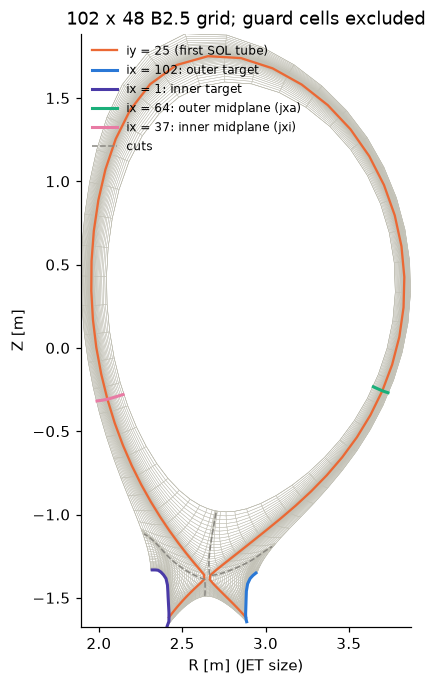

outer-midplane cell (ix=64, iy=25) sits at Z = -0.26 m; geometric outer midplane (max R on iy=25) is ix = 60


In [4]:
crx0 = np.load(DATA / 'geometry' / 'crx.npy')      # (104, 50, 4) corners, JET size
cry0 = np.load(DATA / 'geometry' / 'cry.npy')

def read_b2fgmtry(path, field):
    data, n, found = [], None, False
    with open(path) as f:
        for line in f:
            if n is not None and len(data) >= n:
                break
            if field in line and '*cf:' in line and not found:
                n, found = int(line.split()[2]), True
            elif found:
                data += [float(v) for v in line.split()]
    return np.array(data)

gm = DATA / 'baserun' / 'b2fgmtry'
vol0 = read_b2fgmtry(gm, ' vol ').reshape((NX, NY), order='F')            # m^3, JET size
assert np.allclose(read_b2fgmtry(gm, ' crx ').reshape((NX, NY, 4), order='F'), crx0)
print('nx,ny', read_b2fgmtry(gm, ' nx,ny '), ' cuts', [int(read_b2fgmtry(gm, f' {c} ')[0]) for c in ('leftcut', 'rightcut', 'topcut')])

# polygon vertices in the order used by the release example (corner index 0,1,3,2)
VERTS0 = np.stack([crx0[..., [0, 1, 3, 2]], cry0[..., [0, 1, 3, 2]]], axis=-1).reshape(-1, 4, 2)
RC0, ZC0 = crx0.mean(-1), cry0.mean(-1)             # cell centres

def real(a2d):
    '''Drop guard cells: (104, 50) -> (102, 48).'''
    return a2d[1:-1, 1:-1]

def plot_field(ax, field2d, R=R_JET, log=True, vmin=None, vmax=None, cmap='viridis', zoom=None, title=''):
    '''Colour-map a (104, 50) field on the R-scaled grid. zoom=(R0,R1,Z0,Z1) in unscaled JET metres.'''
    s = R / R_JET
    vals = np.asarray(field2d, dtype=float).ravel()
    ok = np.isfinite(vals) & ((vals > 0) if log else True)
    norm = (mcolors.LogNorm if log else mcolors.Normalize)(vmin=vmin or np.nanmin(vals[ok]), vmax=vmax or np.nanmax(vals[ok]))
    pc = PolyCollection(VERTS0 * s, array=np.where(ok, vals, np.nan), norm=norm, cmap=cmap, edgecolor='none', rasterized=True)
    ax.add_collection(pc)
    lim = zoom or (crx0.min(), crx0.max(), cry0.min(), cry0.max())
    ax.set_xlim(lim[0] * s, lim[1] * s); ax.set_ylim(lim[2] * s, lim[3] * s)
    ax.set_aspect('equal'); ax.grid(False); ax.set_title(title, fontsize=10)
    return pc

fig, ax = plt.subplots(figsize=(5.5, 7))
ax.add_collection(PolyCollection(VERTS0, facecolor='none', edgecolor='#c3c2b7', linewidth=0.3))
ax.plot(RC0[1:-1, IY_SEP], ZC0[1:-1, IY_SEP], color=RCOL['attached'], lw=1.5, label=f'iy = {IY_SEP} (first SOL tube)')
for ix, lab, c in [(IX_OT, 'outer target', '#2a78d6'), (IX_IT, 'inner target', '#4a3aa7'),
                   (IX_OMP, 'outer midplane (jxa)', '#1baf7a'), (IX_IMP, 'inner midplane (jxi)', '#e87ba4')]:
    ax.plot(RC0[ix, 1:-1], ZC0[ix, 1:-1], color=c, lw=2, label=f'ix = {ix}: {lab}')
for ix in (LEFTCUT, RIGHTCUT):
    ax.plot(RC0[ix, 1:-1], ZC0[ix, 1:-1], color='#898781', lw=1, ls='--', label='cuts' if ix == LEFTCUT else None)
ax.set_aspect('equal'); ax.set_xlim(crx0.min(), crx0.max()); ax.set_ylim(cry0.min(), cry0.max())
ax.set_xlabel('R [m] (JET size)'); ax.set_ylabel('Z [m]'); ax.legend(fontsize=8, loc='upper left'); ax.grid(False)
ax.set_title(f'{NX-2} x {NY-2} B2.5 grid; guard cells excluded')
plt.show()
print(f'outer-midplane cell (ix={IX_OMP}, iy={IY_SEP}) sits at Z = {ZC0[IX_OMP, IY_SEP]:+.2f} m; '
      f'geometric outer midplane (max R on iy={IY_SEP}) is ix = {RC0[1:-1, IY_SEP].argmax() + 1}')

## Input parameter space

Table 1 of the paper: `R, B, P_in, D_perp, chi_perp` uniform, `D_puff, N_puff, D_core` log-uniform.
Training runs are a Sobol sequence, test runs are random. The `X_units` rows are the *completed* runs
only; the crash rate as a function of each parameter is a first hint at where SOLPS-ITER is fragile
(and where any surrogate will have to extrapolate).

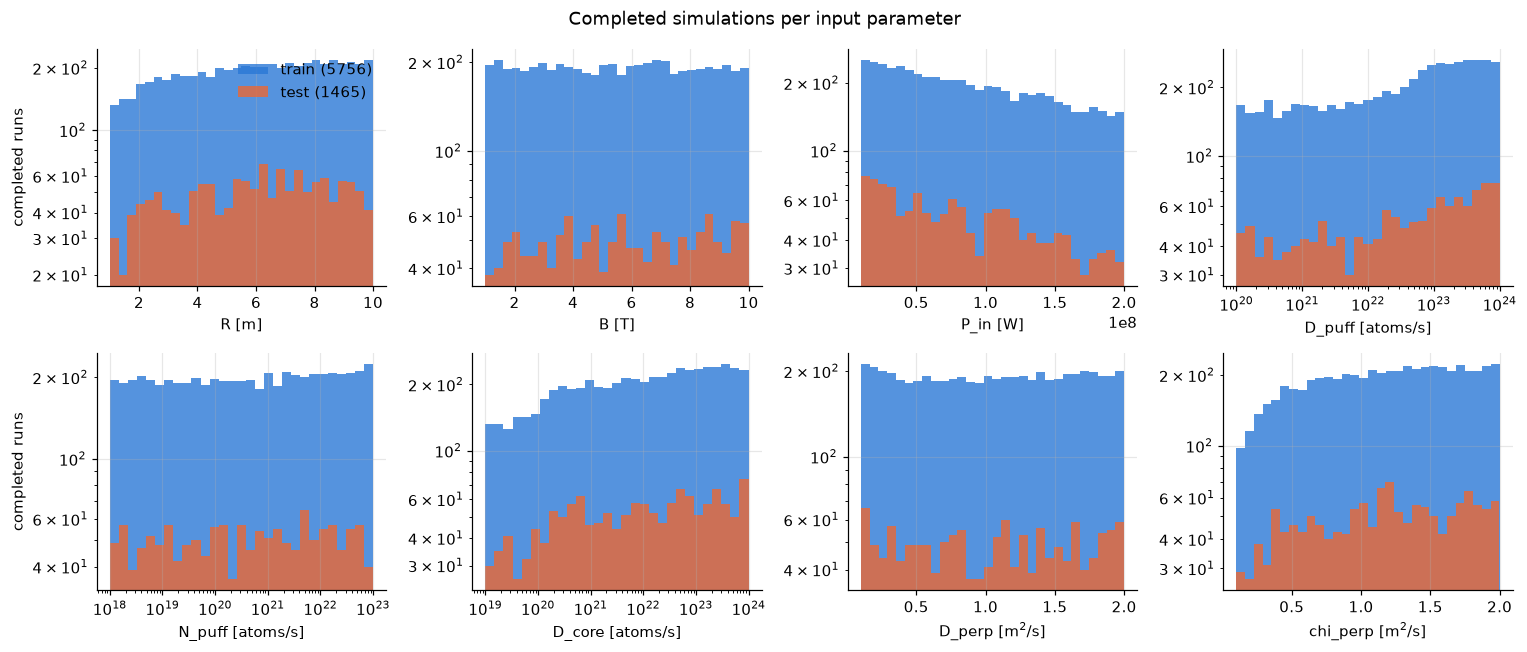

parameter ranges of completed runs (train):
  R                  1 ..         10 m
  B                  1 ..         10 T
  P_in           1e+07 ..      2e+08 W
  D_puff         1e+20 ..   9.99e+23 atoms/s
  N_puff         1e+18 ..   9.99e+22 atoms/s
  D_core         1e+19 ..   9.99e+23 atoms/s
  D_perp           0.1 ..          2 m$^2$/s
  chi_perp       0.101 ..          2 m$^2$/s


In [5]:
fig, axs = plt.subplots(2, 4, figsize=(14, 6))
for j, ax in enumerate(axs.ravel()):
    bins = np.logspace(np.log10(train.X[:, j].min()), np.log10(train.X[:, j].max()), 30) if LOGP[j] else 30
    ax.hist(train.X[:, j], bins=bins, color='#2a78d6', alpha=0.8, label=f'train ({train.n})')
    ax.hist(test.X[:, j], bins=bins, color='#eb6834', alpha=0.8, label=f'test ({test.n})')
    if LOGP[j]: ax.set_xscale('log')
    ax.set_xlabel(f'{PARAMS[j]} [{UNITS[j]}]'); ax.set_yscale('log')
axs[0, 0].legend(); axs[0, 0].set_ylabel('completed runs'); axs[1, 0].set_ylabel('completed runs')
fig.suptitle('Completed simulations per input parameter'); plt.tight_layout(); plt.show()
print('parameter ranges of completed runs (train):')
for j in range(8):
    print(f'  {PARAMS[j]:9s} {train.X[:, j].min():10.3g} .. {train.X[:, j].max():10.3g} {UNITS[j]}')

Crash rate against each parameter, using all attempted runs from `simulations.db` (table `sims`; its
`Tcore` column is the per-channel power `P_in / 2`, and `ntim` the requested number of time steps).
Small machines, high power, weak core fuelling and low `chi_perp` are where SOLPS-ITER diverges most.

using table with columns ['id', 'R', 'B', 'Tcore', 'Dpuff', 'Npuff', 'Dcore', 'Dperp', 'Chi'] -> id id params ['R', 'B', 'Tcore', 'Dpuff', 'Npuff', 'Dcore', 'Dperp', 'Chi']
8192 attempted, 5756 completed, 2436 failed


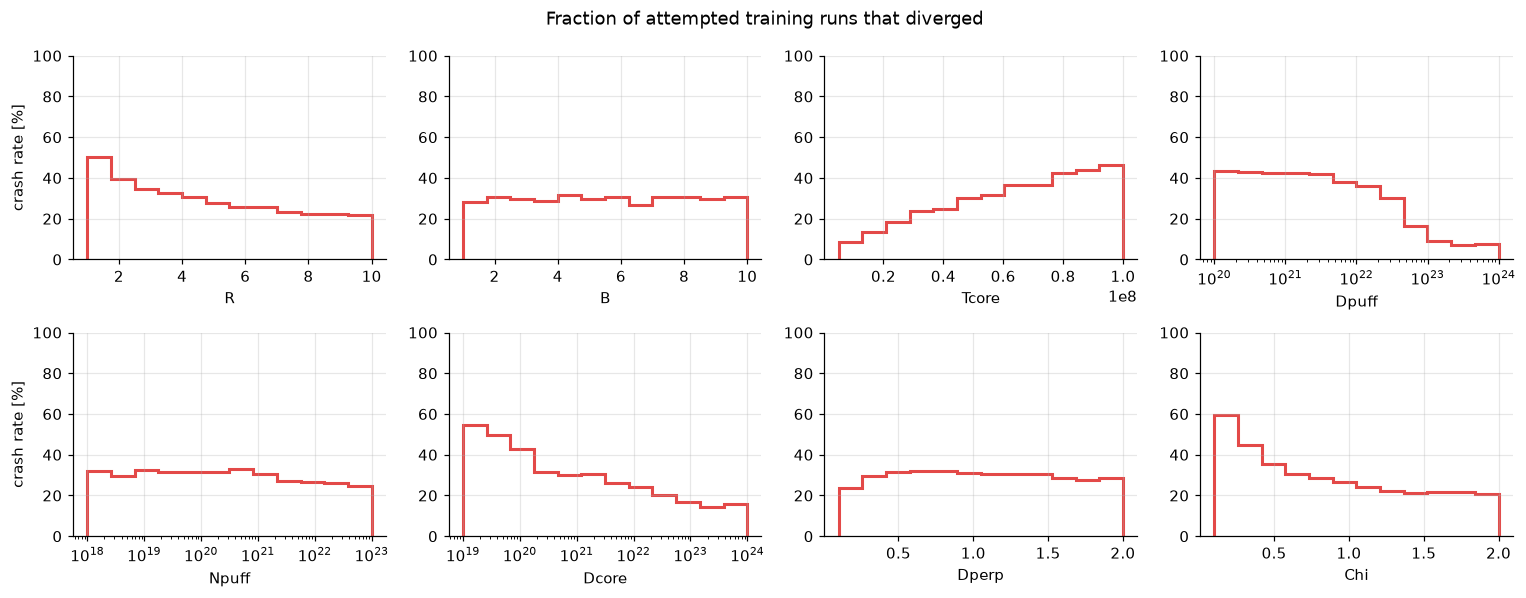

In [6]:
def attempted_params(split):
    '''(sim_id, X[8], completed?) for every attempted run, read from simulations.db.'''
    db = split.params_db()
    (rows, cols), = [(r, c) for r, c in db.values() if len(r) >= split.n]   # the parameter table
    num = [j for j in range(len(cols)) if all(isinstance(r[j], (int, float)) for r in rows)]
    id_col = num[0]                                            # first numeric column = sim_id
    par = num[1:9]                                             # next eight numeric columns = inputs
    print('using table with columns', cols, '-> id', cols[id_col], 'params', [cols[j] for j in par])
    ids = np.array([r[id_col] for r in rows], dtype=int)
    X = np.array([[r[j] for j in par] for r in rows], dtype=float)
    done = np.isin(ids, split.completed)
    return ids, X, done, [cols[j] for j in par]

ids_all, X_all, done_all, cols_all = attempted_params(train)
print(f'{len(ids_all)} attempted, {done_all.sum()} completed, {(~done_all).sum()} failed')

fig, axs = plt.subplots(2, 4, figsize=(14, 5.5))
for j, ax in enumerate(axs.ravel()):
    x = X_all[:, j]
    if LOGP[j] and x.max() > 100 * x.min():
        edges = np.logspace(np.log10(x.min()), np.log10(x.max()), 13); ax.set_xscale('log')
    else:
        edges = np.linspace(x.min(), x.max(), 13)
    k = np.clip(np.digitize(x, edges) - 1, 0, 11)
    rate = np.array([(~done_all[k == b]).mean() if (k == b).any() else np.nan for b in range(12)])
    ax.stairs(100 * rate, edges, color='#e34948', lw=2)
    ax.set_xlabel(cols_all[j]); ax.set_ylim(0, 100)
axs[0, 0].set_ylabel('crash rate [%]'); axs[1, 0].set_ylabel('crash rate [%]')
fig.suptitle('Fraction of attempted training runs that diverged'); plt.tight_layout(); plt.show()

## Regimes (paper Section 2, Figure 1)

Classification by the electron temperature just outside the separatrix at the outer midplane
(`Te_omp`) and at the outer target (`Te_ot`):

| regime | rule |
|---|---|
| cold core | `Te_omp < 10 eV` (takes precedence) |
| sheath-limited | `Te_ot / Te_omp >= 0.8` |
| attached | `Te_ot > 5 eV` |
| detached | `Te_ot <= 5 eV` |

Paper (training set): 27 % sheath-limited, 38 % attached, 20 % detached, the rest cold core; peaks of the
attached/detached `Te_omp` distributions at 179 eV and 123 eV.

In [7]:
def sep_scalars(split):
    '''Separatrix-adjacent scalars at OMP and outer target, in eV and m^-3.'''
    te, ti, na = split['te'], split['ti'], split['na']
    d = {}
    for tag, ix in (('omp', IX_OMP), ('ot', IX_OT)):
        d[f'te_{tag}'] = np.asarray(te[:, ix, IY_SEP]) / EV
        d[f'ti_{tag}'] = np.asarray(ti[:, ix, IY_SEP]) / EV
        n_a = np.asarray(na[:, ix, IY_SEP, :])                    # (n_sim, ns)
        d[f'ne_{tag}'] = n_a @ ZA                                  # quasineutrality
        d[f'nD0_{tag}'] = n_a[:, 0]; d[f'nN0_{tag}'] = n_a[:, 2]
        d[f'pe_{tag}'] = d[f'ne_{tag}'] * d[f'te_{tag}'] * EV      # Pa
    return d

def classify(te_omp, te_ot):
    reg = np.full(len(te_omp), 'detached', dtype=object)
    reg[te_ot > 5] = 'attached'
    reg[te_ot / te_omp >= 0.8] = 'sheath-limited'
    reg[te_omp < 10] = 'cold core'
    return reg

t0 = time.time()
S = {name: sep_scalars(sp) for name, sp in (('train', train), ('test', test))}
for name, sp in (('train', train), ('test', test)):
    S[name]['regime'] = classify(S[name]['te_omp'], S[name]['te_ot'])
    S[name]['X'] = sp.X
    for q in ('psol', 'pwmxap', 'fnixap'):
        S[name][q] = np.asarray(sp[q])
print(f'separatrix scalars read in {time.time() - t0:.1f} s')
for name in ('train', 'test'):
    reg = S[name]['regime']
    print(f'{name}: ' + ', '.join(f'{r} {100 * (reg == r).mean():.0f} %' for r in REGIMES))

separatrix scalars read in 2.4 s
train: sheath-limited 27 %, attached 38 %, detached 20 %, cold core 14 %
test: sheath-limited 29 %, attached 36 %, detached 21 %, cold core 14 %


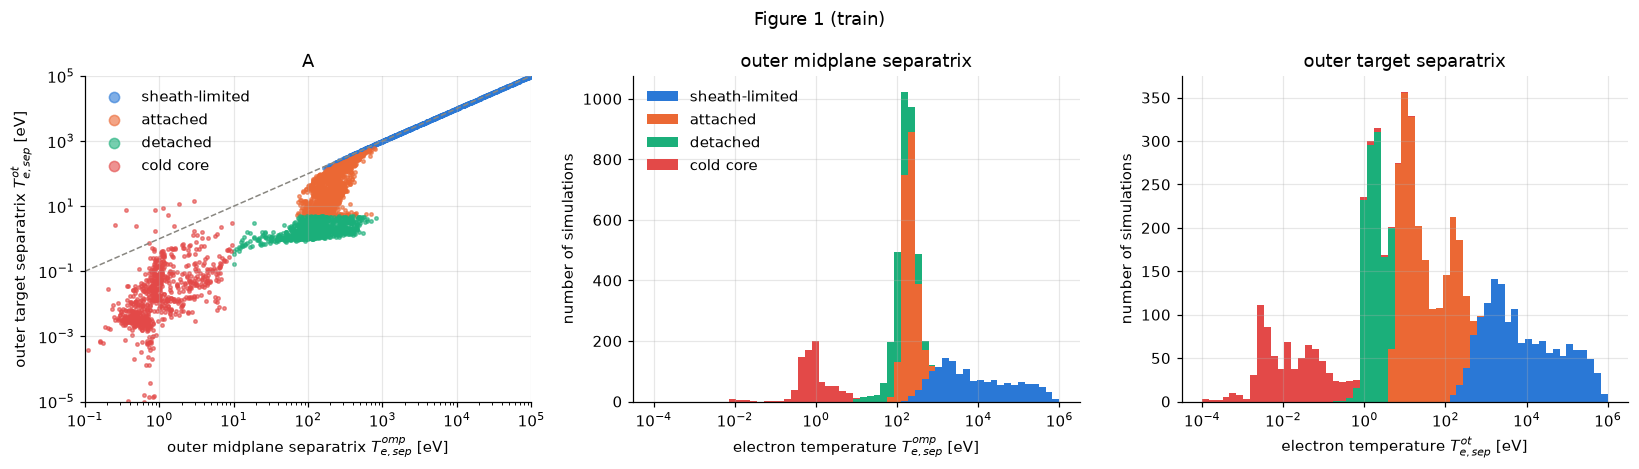

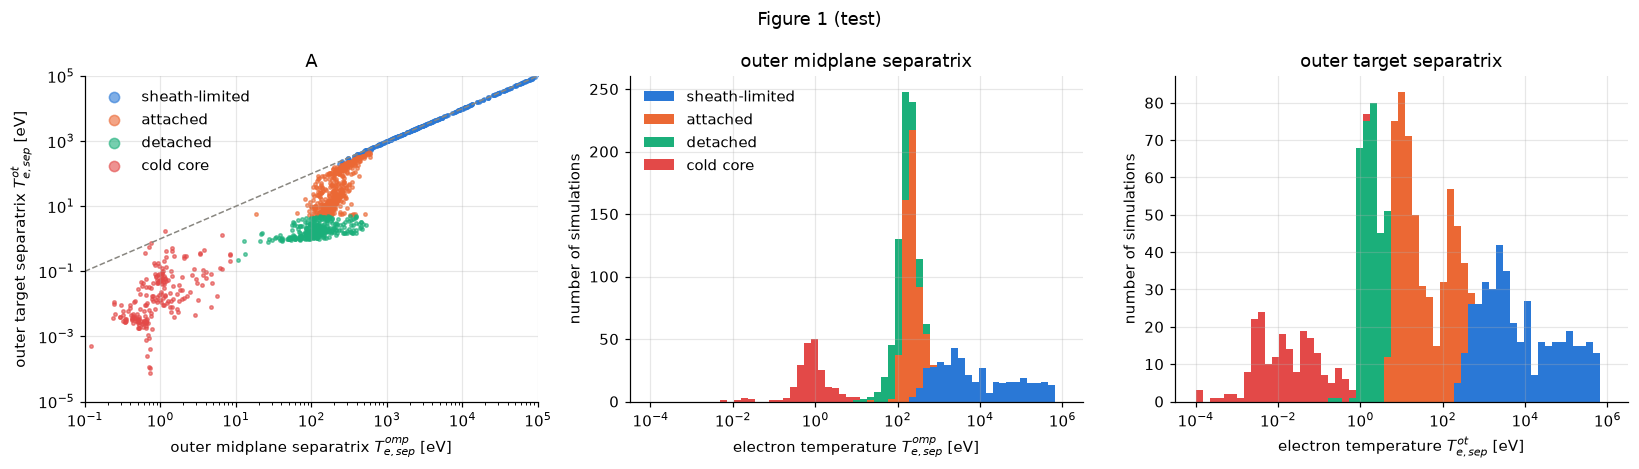

attached: Te_omp distribution peaks at 220 eV, median 204 eV
detached: Te_omp distribution peaks at 123 eV, median 118 eV


In [8]:
def fig1(D, title):
    reg = D['regime']
    fig, axs = plt.subplots(1, 3, figsize=(15, 4.3))
    ax = axs[0]
    for r in REGIMES:
        m = reg == r
        ax.scatter(D['te_omp'][m], D['te_ot'][m], s=5, color=RCOL[r], alpha=0.6, label=r, rasterized=True)
    ax.plot([1e-1, 1e5], [1e-1, 1e5], color='#898781', lw=1, ls='--')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(1e-1, 1e5); ax.set_ylim(1e-5, 1e5)
    ax.set_xlabel('outer midplane separatrix $T_{e,sep}^{omp}$ [eV]'); ax.set_ylabel('outer target separatrix $T_{e,sep}^{ot}$ [eV]')
    ax.legend(markerscale=3, loc='upper left'); ax.set_title('A')
    for ax, key, lab in ((axs[1], 'te_omp', 'outer midplane'), (axs[2], 'te_ot', 'outer target')):
        x = D[key]
        bins = np.logspace(-4, 6, 60)
        ax.hist([x[reg == r] for r in REGIMES], bins=bins, stacked=True, color=[RCOL[r] for r in REGIMES], label=REGIMES)
        ax.set_xscale('log'); ax.set_xlabel(f'electron temperature $T_{{e,sep}}^{{{"omp" if "omp" in key else "ot"}}}$ [eV]')
        ax.set_ylabel('number of simulations'); ax.set_title(f'{lab} separatrix')
    axs[1].legend(); fig.suptitle(title); plt.tight_layout(); plt.show()

fig1(S['train'], 'Figure 1 (train)')
fig1(S['test'], 'Figure 1 (test)')

for r in ('attached', 'detached'):
    x = S['train']['te_omp'][S['train']['regime'] == r]
    h, e = np.histogram(np.log10(x), bins=80)
    print(f'{r}: Te_omp distribution peaks at {10 ** (0.5 * (e[h.argmax()] + e[h.argmax() + 1])):.0f} eV, median {np.median(x):.0f} eV')

### Where the regimes live in parameter space

Not in the paper, but this is what a surrogate is asked to interpolate: which inputs decide the regime.
Two projections, one at the fuelling end (`D_puff`, `N_puff`) and one at the machine end (`R`, `P_in`).

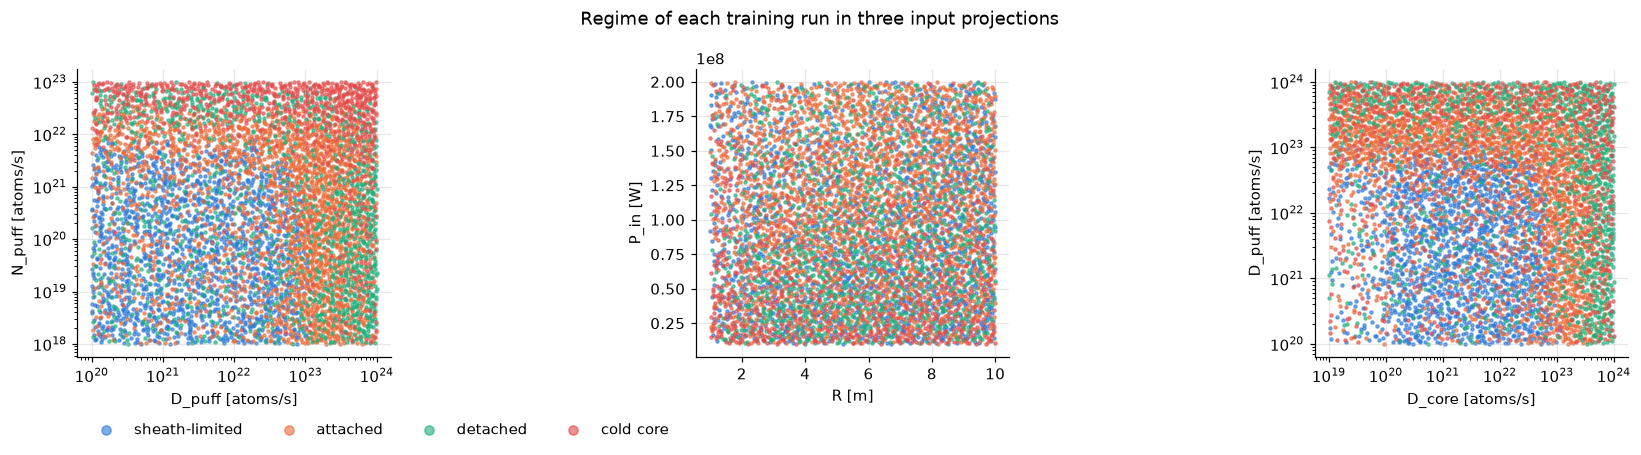

In [9]:
D = S['train']; reg = D['regime']; X = D['X']
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (jx, jy) in zip(axs, [(3, 4), (0, 2), (5, 3)]):
    for r in REGIMES:
        m = reg == r
        ax.scatter(X[m, jx], X[m, jy], s=4, color=RCOL[r], alpha=0.6, label=r, rasterized=True)
    if LOGP[jx]: ax.set_xscale('log')
    if LOGP[jy]: ax.set_yscale('log')
    ax.set_xlabel(f'{PARAMS[jx]} [{UNITS[jx]}]'); ax.set_ylabel(f'{PARAMS[jy]} [{UNITS[jy]}]')
axs[0].legend(markerscale=3, loc='upper left', bbox_to_anchor=(0, -0.18), ncol=4); fig.suptitle('Regime of each training run in three input projections'); plt.tight_layout(); plt.show()

## 2D fields (paper Figure 2)

One test simulation, full domain and divertor zoom: `Te`, `ne`, `n_D0`, `n_N0` on the R-scaled grid.
Pick a case in the attached regime with `Te_omp` between 100 and 300 eV, as in the paper's example.

test row 755, sim_id 337, regime attached, Te_omp 135 eV, Te_ot 11.2 eV
inputs: R = 8.77, B = 6.9, P_in = 5.05e+07, D_puff = 2.91e+23, N_puff = 1.18e+21, D_core = 7.57e+21, D_perp = 0.729, chi_perp = 1.13


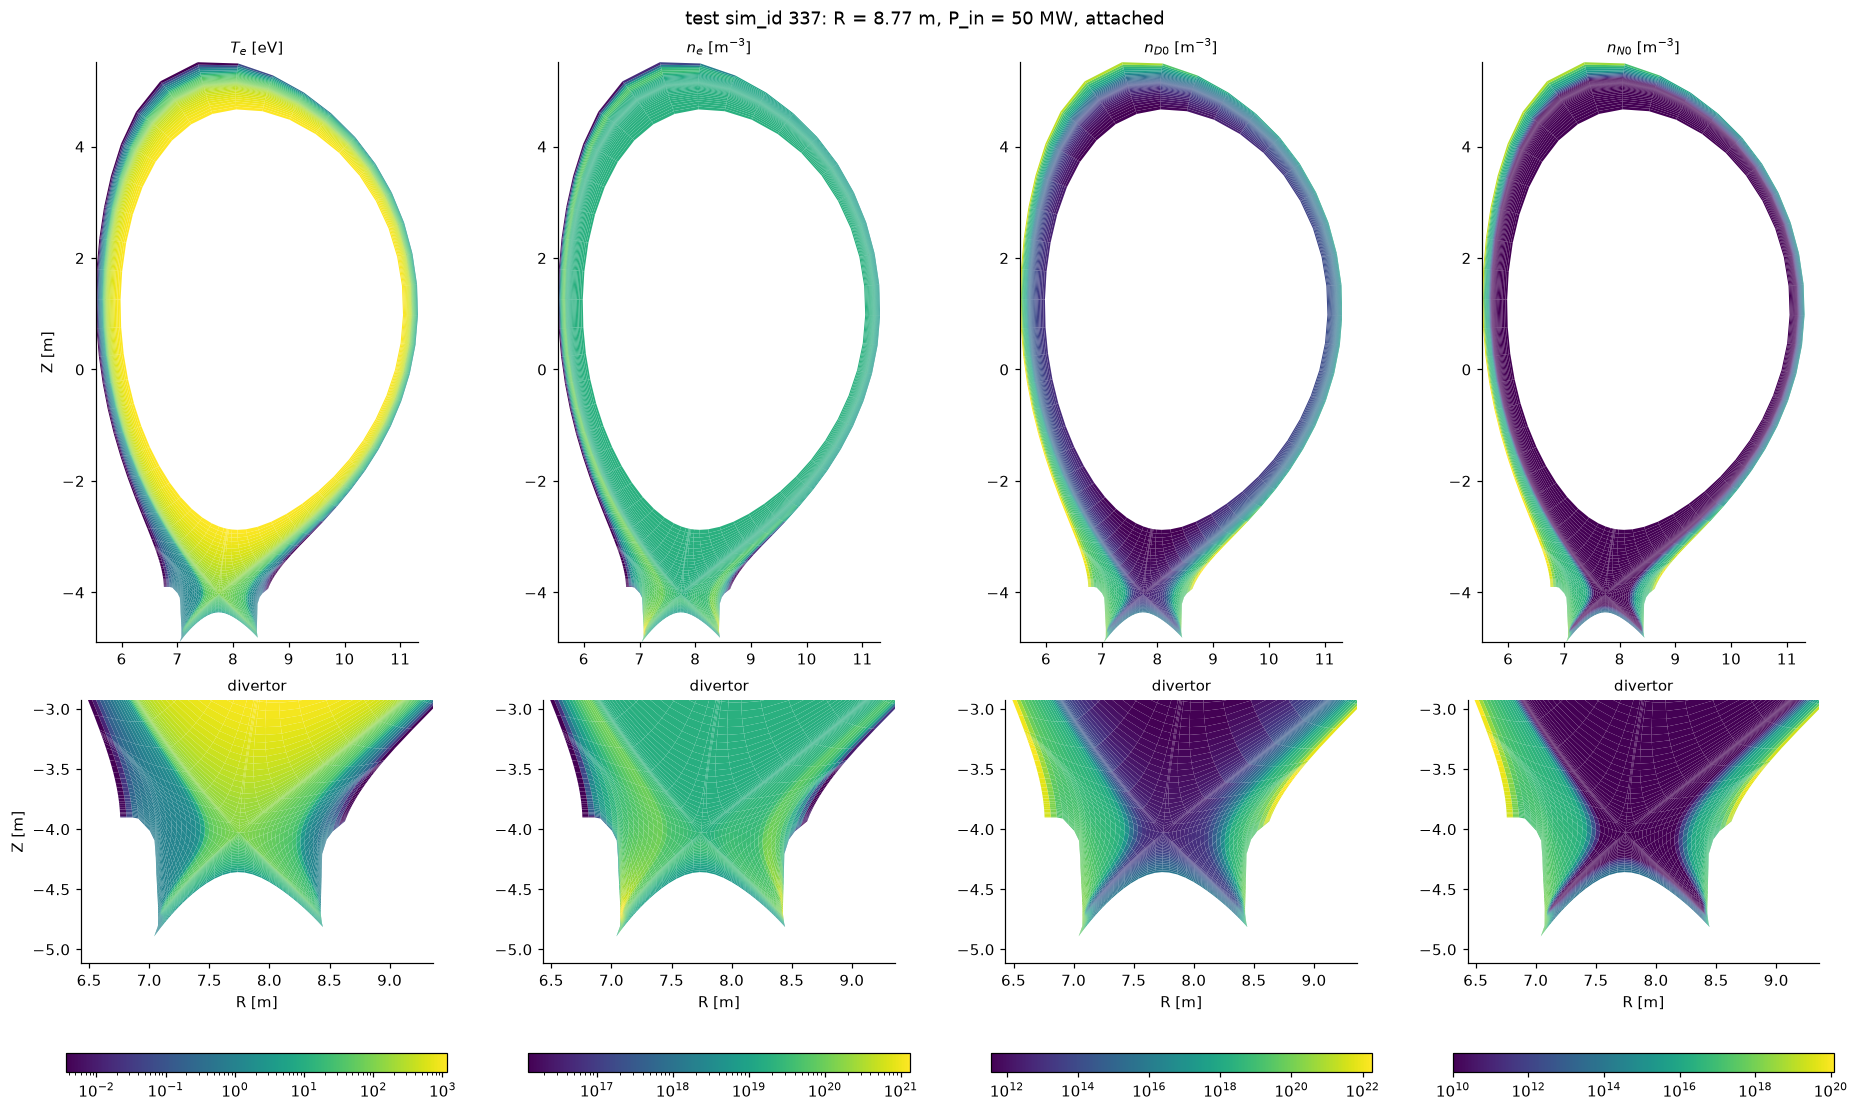

In [10]:
D = S['test']
cand = np.where((D['regime'] == 'attached') & (D['te_omp'] > 100) & (D['te_omp'] < 300))[0]
k = int(cand[len(cand) // 2]) if len(cand) else 0
R_k = test.X[k, 0]
print(f'test row {k}, sim_id {test.completed[k]}, regime {D["regime"][k]}, Te_omp {D["te_omp"][k]:.0f} eV, Te_ot {D["te_ot"][k]:.1f} eV')
print('inputs: ' + ', '.join(f'{p} = {v:.3g}' for p, v in zip(PARAMS, test.X[k])))

na_k = np.asarray(test['na'][k])                            # (104, 50, 10)
fields = {'$T_e$ [eV]': np.asarray(test['te'][k]) / EV,
          '$n_e$ [m$^{-3}$]': na_k @ ZA,
          '$n_{D0}$ [m$^{-3}$]': na_k[..., 0],
          '$n_{N0}$ [m$^{-3}$]': na_k[..., 2]}
ZOOM = (2.2, 3.2, -1.75, -1.0)                              # divertor, unscaled metres
fig, axs = plt.subplots(2, 4, figsize=(17, 10), gridspec_kw={'height_ratios': [2.2, 1]}, constrained_layout=True)
for j, (lab, f) in enumerate(fields.items()):
    f = f.copy(); f[0, :] = f[-1, :] = f[:, 0] = f[:, -1] = np.nan       # hide guard cells
    vmin, vmax = np.nanpercentile(f[f > 0], [1, 99.9])
    pc = plot_field(axs[0, j], f, R=R_k, vmin=vmin, vmax=vmax, title=lab)
    plot_field(axs[1, j], f, R=R_k, vmin=vmin, vmax=vmax, zoom=ZOOM, title='divertor')
    fig.colorbar(pc, ax=axs[1, j], location='bottom', shrink=0.9, pad=0.15)
for ax in axs[:, 0]: ax.set_ylabel('Z [m]')
for ax in axs[1]: ax.set_xlabel('R [m]')
fig.suptitle(f'test sim_id {test.completed[k]}: R = {R_k:.2f} m, P_in = {test.X[k, 2] / 1e6:.0f} MW, {D["regime"][k]}')
plt.show()

## Outer target profiles (paper Figure 3)

`Te` along the outer target for eight test cases spanning the regimes, against the distance along the
plate (from the private-flux corner). The paper points out a `Te` spike at the private-flux edge of the
outer target in low-temperature cases, an artefact of the fluid-neutral pumping boundary.

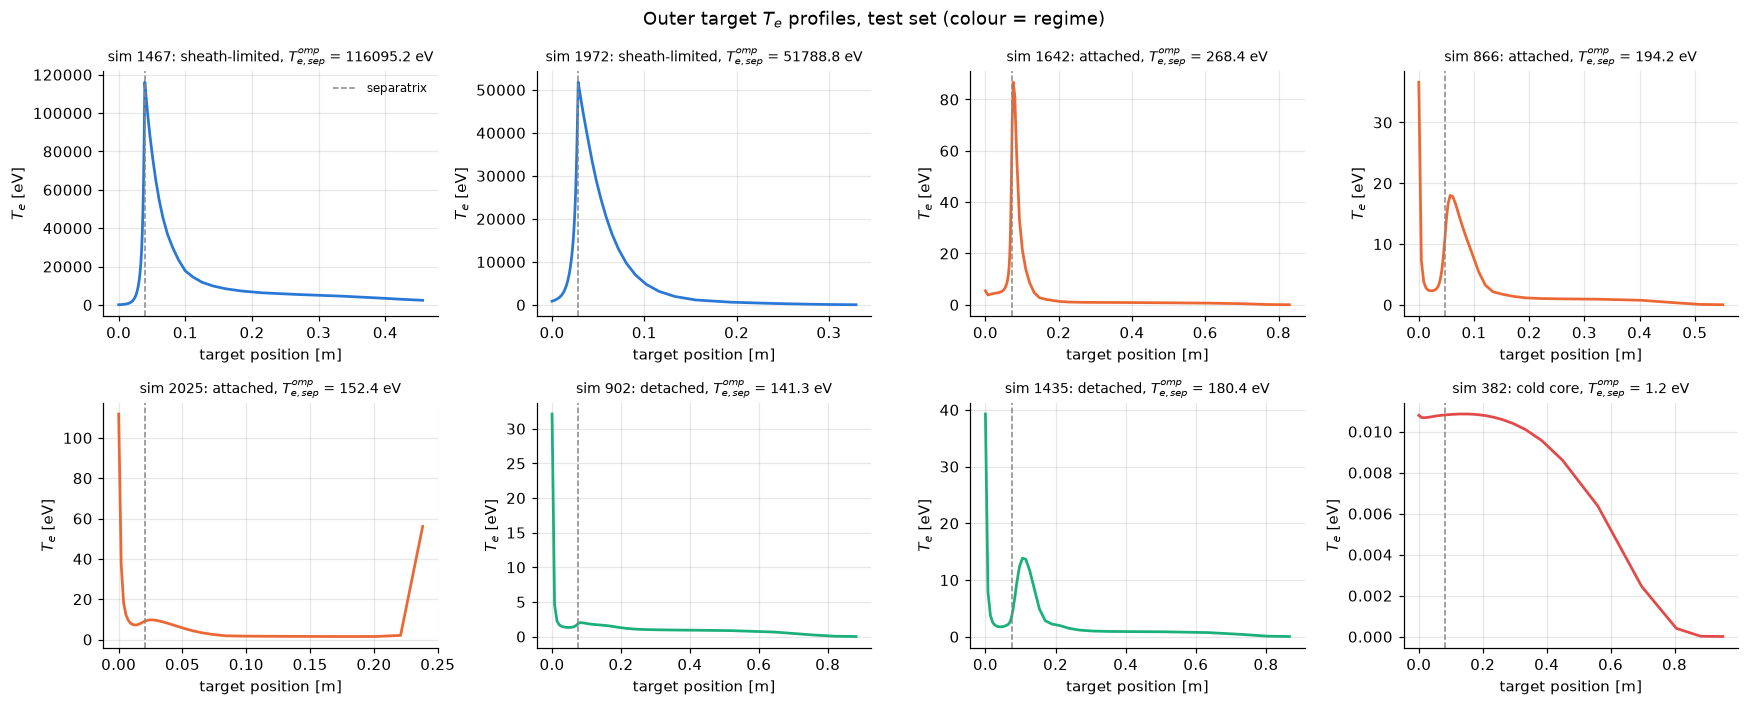

In [11]:
def target_position(R):
    '''Cumulative distance [m] along the outer target between real-cell centres, R-scaled.'''
    r, z = RC0[IX_OT, 1:-1] * R / R_JET, ZC0[IX_OT, 1:-1] * R / R_JET
    return np.concatenate([[0], np.cumsum(np.hypot(np.diff(r), np.diff(z)))])

D = S['test']; rng = np.random.default_rng(0)
picks = []
for r, n in (('sheath-limited', 2), ('attached', 3), ('detached', 2), ('cold core', 1)):
    idx = np.where(D['regime'] == r)[0]
    picks += list(rng.choice(idx, size=min(n, len(idx)), replace=False))
fig, axs = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, k in zip(axs.ravel(), picks):
    te_t = np.asarray(test['te'][k, IX_OT, 1:-1]) / EV
    s = target_position(test.X[k, 0])
    ax.plot(s, te_t, color=RCOL[D['regime'][k]], lw=1.8)
    ax.axvline(s[IY_SEP - 1], color='#898781', lw=1, ls='--', label='separatrix')
    ax.set_title(f'sim {test.completed[k]}: {D["regime"][k]}, $T_{{e,sep}}^{{omp}}$ = {D["te_omp"][k]:.1f} eV', fontsize=9)
    ax.set_xlabel('target position [m]'); ax.set_ylabel('$T_e$ [eV]')
axs[0, 0].legend(loc='upper right', fontsize=8)
fig.suptitle('Outer target $T_e$ profiles, test set (colour = regime)'); plt.tight_layout(); plt.show()

## Scalar QoIs (paper Section 5): `P_SOL`, peak target heat flux, target ion flux

The release ships the three QoIs that SOLPS-NN predicts directly (`psol`, `pwmxap`, `fnixap`). Their
statistics per regime set the scale of the "median absolute error" columns in Table 4.

psol    sheath-limited: median 88.6  attached: median 112  detached: median 69.6  cold core: median 2.07
pwmxap  sheath-limited: median 15.1  attached: median 22.2  detached: median 6.24  cold core: median 9.24e-06
fnixap  sheath-limited: median 4.68e+21  attached: median 3.63e+24  detached: median 1.87e+24  cold core: median 8.68e+16


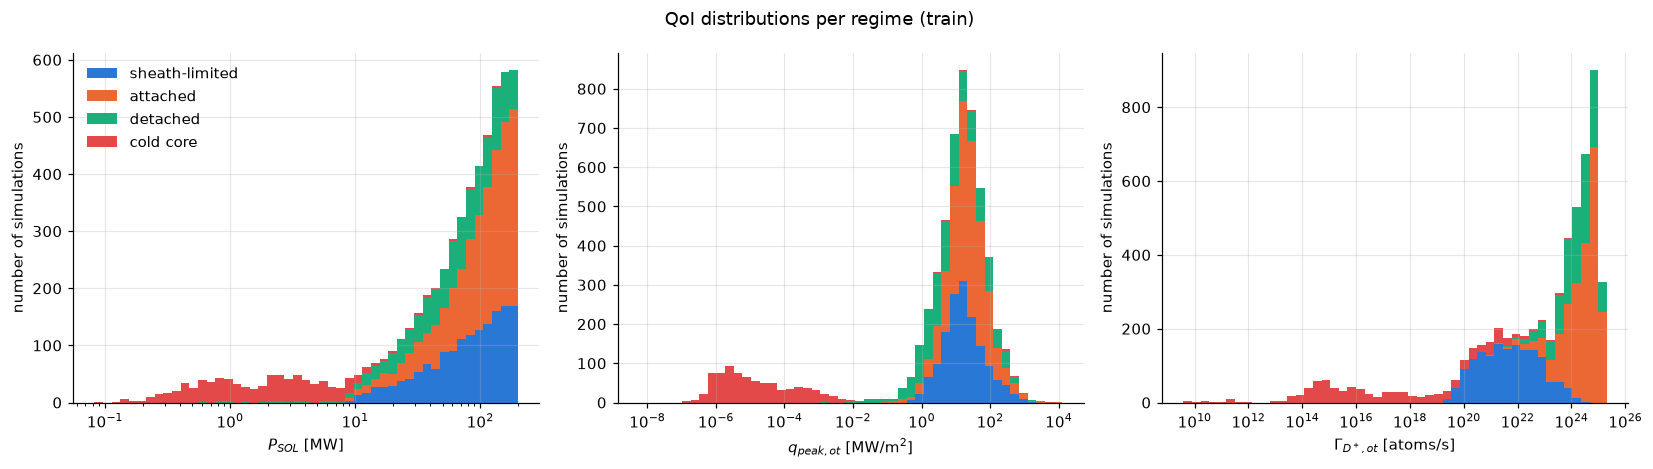

In [12]:
D = S['train']; reg = D['regime']; X = D['X']
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (q, lab, sc) in zip(axs, [('psol', '$P_{SOL}$ [MW]', 1e-6), ('pwmxap', '$q_{peak,ot}$ [MW/m$^2$]', 1e-6), ('fnixap', '$\\Gamma_{D^+,ot}$ [atoms/s]', 1)]):
    v = D[q] * sc
    pos = v[v > 0]
    bins = np.logspace(np.log10(pos.min()), np.log10(pos.max()), 50)
    ax.hist([v[reg == r] for r in REGIMES], bins=bins, stacked=True, color=[RCOL[r] for r in REGIMES], label=REGIMES)
    ax.set_xscale('log'); ax.set_xlabel(lab); ax.set_ylabel('number of simulations')
    print(f'{q:7s} ' + '  '.join(f'{r}: median {np.median(v[reg == r]):.3g}' for r in REGIMES))
axs[0].legend(); fig.suptitle('QoI distributions per regime (train)'); plt.tight_layout(); plt.show()

**Power accounting.** `P_SOL / P_in` is the fraction of the input power that crosses the separatrix,
i.e. 1 minus the fraction radiated inside the confined region of the grid. In the cold-core regime almost
nothing reaches the SOL.

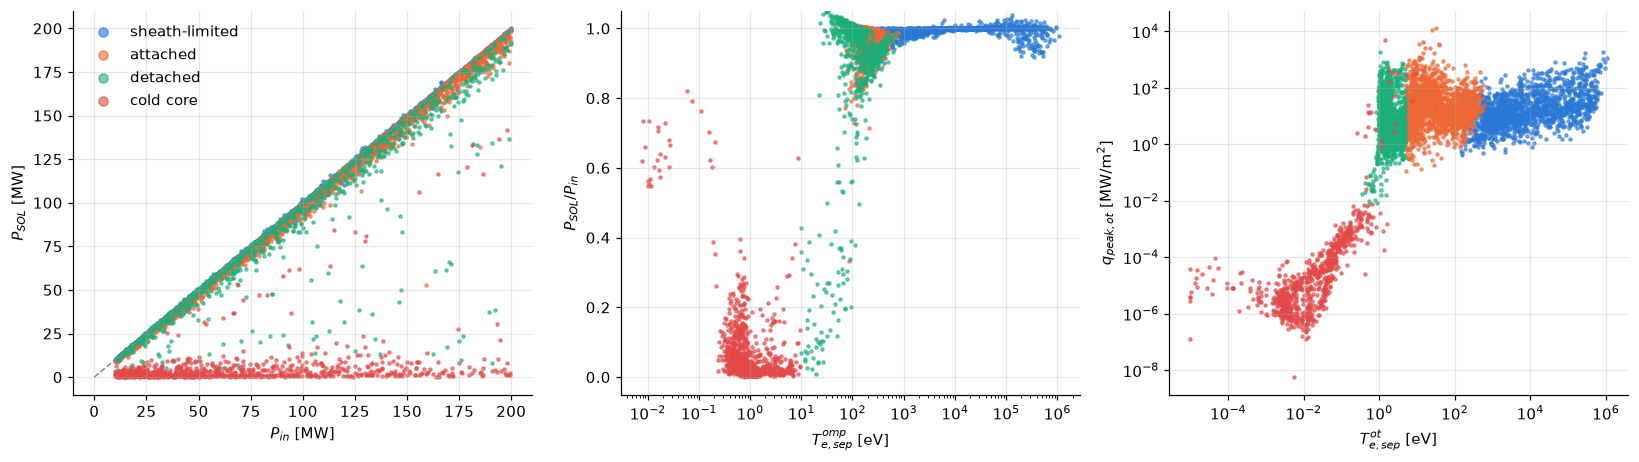

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3))
for r in REGIMES:
    m = reg == r
    axs[0].scatter(X[m, 2] / 1e6, D['psol'][m] / 1e6, s=4, color=RCOL[r], alpha=0.6, label=r, rasterized=True)
    axs[1].scatter(D['te_omp'][m], D['psol'][m] / X[m, 2], s=4, color=RCOL[r], alpha=0.6, rasterized=True)
    axs[2].scatter(D['te_ot'][m], D['pwmxap'][m] / 1e6, s=4, color=RCOL[r], alpha=0.6, rasterized=True)
axs[0].plot([0, 200], [0, 200], color='#898781', lw=1, ls='--'); axs[0].set_xlabel('$P_{in}$ [MW]'); axs[0].set_ylabel('$P_{SOL}$ [MW]'); axs[0].legend(markerscale=3)
axs[1].set_xscale('log'); axs[1].set_xlabel('$T_{e,sep}^{omp}$ [eV]'); axs[1].set_ylabel('$P_{SOL} / P_{in}$'); axs[1].set_ylim(-0.05, 1.05)
axs[2].set_xscale('log'); axs[2].set_yscale('log'); axs[2].set_xlabel('$T_{e,sep}^{ot}$ [eV]'); axs[2].set_ylabel('$q_{peak,ot}$ [MW/m$^2$]')
plt.tight_layout(); plt.show()

### Detachment signatures across the database

The paper diagnoses detachment on a *scan* (rollover of `Gamma_D+,ot` with upstream density, Figure 6D).
On the full database the same physics shows up as (left) the target ion flux against upstream density,
(middle) the target-to-upstream electron pressure ratio dropping below one as `Te_ot` falls (momentum
loss), and (right) the divertor nitrogen concentration, `c_N,div = int(sum n_N) dV / int n_e dV` over
the outer divertor leg (`ix > rightcut`), which is the paper's detachment-access variable. The paper's
definition counts neutral nitrogen too, so `c_N,div` exceeds one when the outer leg fills with nitrogen
gas (cold-core runs); the axis is clipped at 100.

c_N,div for 5756 runs in 2 s
26 % of runs have c_N,div > 1 (neutral nitrogen gas exceeding n_e in the outer leg; 92 % of the cold-core runs)


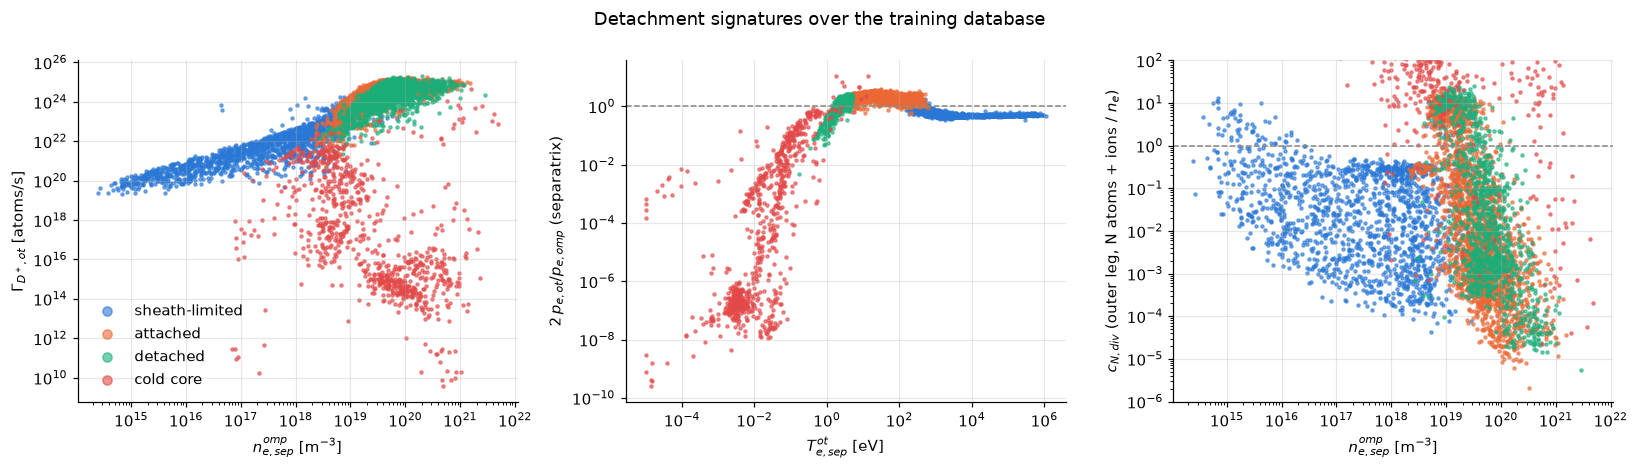

In [14]:
def divertor_cN(split, rows):
    '''Volume-averaged nitrogen concentration over the outer divertor leg (all N charge states / ne).'''
    sl = slice(RIGHTCUT + 1, NX - 1)                          # outer leg, real cells only
    v = vol0[sl, 1:-1]                                        # volume scales as R^3, cancels in the ratio
    out = np.empty(len(rows))
    for i, k in enumerate(rows):
        n = np.asarray(split['na'][k, sl, 1:-1, :])           # (nleg, 48, 10)
        out[i] = (n[..., 2:].sum(-1) * v).sum() / ((n @ ZA) * v).sum()
    return out

t0 = time.time()
cN = divertor_cN(train, range(train.n)); S['train']['cN_div'] = cN
print(f'c_N,div for {train.n} runs in {time.time() - t0:.0f} s')

fig, axs = plt.subplots(1, 3, figsize=(15, 4.3))
for r in REGIMES:
    m = reg == r
    axs[0].scatter(D['ne_omp'][m], D['fnixap'][m], s=4, color=RCOL[r], alpha=0.6, label=r, rasterized=True)
    axs[1].scatter(D['te_ot'][m], 2 * D['pe_ot'][m] / D['pe_omp'][m], s=4, color=RCOL[r], alpha=0.6, rasterized=True)
    axs[2].scatter(D['ne_omp'][m], cN[m], s=4, color=RCOL[r], alpha=0.6, rasterized=True)
axs[0].set_xscale('log'); axs[0].set_yscale('log'); axs[0].set_xlabel('$n_{e,sep}^{omp}$ [m$^{-3}$]'); axs[0].set_ylabel('$\\Gamma_{D^+,ot}$ [atoms/s]'); axs[0].legend(markerscale=3)
axs[1].set_xscale('log'); axs[1].set_yscale('log'); axs[1].axhline(1, color='#898781', lw=1, ls='--')
axs[1].set_xlabel('$T_{e,sep}^{ot}$ [eV]'); axs[1].set_ylabel('$2\\,p_{e,ot} / p_{e,omp}$ (separatrix)')
axs[2].set_xscale('log'); axs[2].set_yscale('log'); axs[2].set_ylim(1e-6, 1e2); axs[2].axhline(1, color='#898781', lw=1, ls='--')
axs[2].set_xlabel('$n_{e,sep}^{omp}$ [m$^{-3}$]'); axs[2].set_ylabel('$c_{N,div}$ (outer leg, N atoms + ions / $n_e$)')
print(f'{100 * (cN > 1).mean():.0f} % of runs have c_N,div > 1 (neutral nitrogen gas exceeding n_e in the outer leg; '
      f'{100 * (cN[reg == "cold core"] > 1).mean():.0f} % of the cold-core runs)')
fig.suptitle('Detachment signatures over the training database'); plt.tight_layout(); plt.show()

## Data quality

Things a training pipeline must know before normalising: non-finite values, the dynamic range per
field (the paper uses a per-cell quantile transform for exactly this reason), negative densities, and
the private-flux `Te` spike at the outer target. Expect the density floor `1e10 m^-3` (`b2mndr_na_min`
in `b2mn.dat`) everywhere a species is absent, and sheath-limited runs with `Te` up to ~1e6 eV: the
low-puff, high-power corner of the box is a collisionless plasma the fluid code still integrates.

In [15]:
def field_stats(split, item, rows=None):
    '''min / max / non-finite / negative counts over real cells, one pass over the file; per species if 4-D.'''
    a = split[item]
    rows = range(split.n) if rows is None else rows
    nsp = a.shape[3] if a.ndim == 4 else 1
    mn, mx = np.full(nsp, np.inf), np.full(nsp, -np.inf)
    nonfinite, neg = np.zeros(nsp, int), np.zeros(nsp, int)
    for k in rows:
        f = np.asarray(a[k, 1:-1, 1:-1]).reshape(-1, nsp).astype(float)
        ok = np.isfinite(f)
        nonfinite += (~ok).sum(0); neg += ((f < 0) & ok).sum(0)
        f = np.where(ok, f, np.nan)
        mn = np.fmin(mn, np.nanmin(f, 0)); mx = np.fmax(mx, np.nanmax(f, 0))
    return mn, mx, nonfinite, neg

t0 = time.time()
print(f'{"field":8s} {"min":>10s} {"max":>10s}  non-finite  negative   (train, real cells, eV / m^-3 / m/s)')
for item in ('te', 'ti', 'na', 'ua'):
    mn, mx, nf, ng = field_stats(train, item)
    scale = 1 / EV if item in ('te', 'ti') else 1
    for sidx in range(len(mn)):
        name = item if len(mn) == 1 else f'{item}_{SPECIES[sidx]}'
        print(f'{name:8s} {mn[sidx] * scale:10.3g} {mx[sidx] * scale:10.3g}  {nf[sidx]:10d}  {ng[sidx]:8d}')
print(f'({time.time() - t0:.0f} s)')

field           min        max  non-finite  negative   (train, real cells, eV / m^-3 / m/s)


te            1e-05   1.45e+06           0         0


ti            1e-05   2.46e+05           0         0


na_D0         1e+10   1.19e+27           0         0
na_D1         1e+10   1.52e+23           0         0
na_N0         1e+10   2.28e+27           0         0
na_N1         1e+10   9.27e+21           0         0
na_N2         1e+10   7.61e+21           0         0
na_N3         1e+10   1.28e+21           0         0
na_N4         1e+10   2.94e+20           0         0
na_N5         1e+10   4.55e+20           0         0
na_N6         1e+10   1.03e+20           0         0
na_N7         1e+10   4.34e+19           0         0


ua_D0     -1.35e+05   1.89e+05           0  15988519
ua_D1     -8.15e+06   9.23e+06           0  16127407
ua_N0      -5.8e+04   4.64e+04           0  14986868
ua_N1     -2.71e+06   4.04e+06           0  16033503
ua_N2     -4.06e+06   4.76e+06           0  16104286
ua_N3     -7.19e+06   6.65e+06           0  16093455
ua_N4     -7.14e+06   1.31e+07           0  15815773
ua_N5     -1.59e+07   1.95e+07           0  15580454
ua_N6     -1.61e+07   2.11e+07           0  15732426
ua_N7     -1.64e+07   2.12e+07           0  16059987
(10 s)


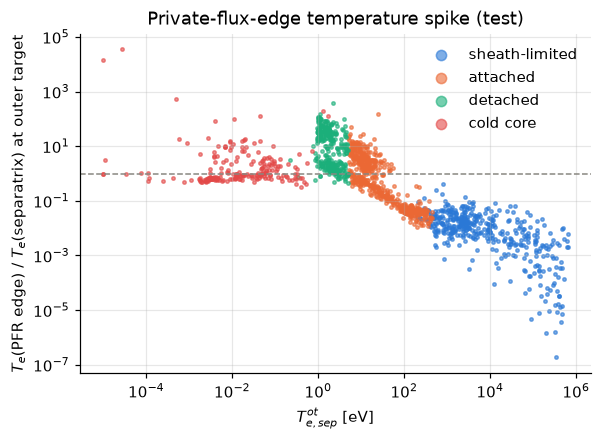

25 % of test runs have a PFR-edge Te more than 3x the separatrix value


In [16]:
# Outer-target Te spike at the private-flux edge: ratio of the first PFR cell to the separatrix cell.
D = S['test']
te_t = np.asarray(test['te'][:, IX_OT, 1:-1]) / EV                 # (n_sim, 48)
spike = te_t[:, 0] / te_t[:, IY_SEP - 1]
fig, ax = plt.subplots(figsize=(6, 4))
for r in REGIMES:
    m = D['regime'] == r
    ax.scatter(D['te_ot'][m], spike[m], s=5, color=RCOL[r], alpha=0.6, label=r, rasterized=True)
ax.axhline(1, color='#898781', lw=1, ls='--'); ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('$T_{e,sep}^{ot}$ [eV]'); ax.set_ylabel('$T_e$(PFR edge) / $T_e$(separatrix) at outer target'); ax.legend(markerscale=3)
ax.set_title('Private-flux-edge temperature spike (test)'); plt.show()
print(f'{100 * (spike > 3).mean():.0f} % of test runs have a PFR-edge Te more than 3x the separatrix value')

## Mapping onto the `solstice` canonical schema

What the release gives, in the vocabulary of `docs/specs/data_schema.md`:

| schema group | available here | notes |
|---|---|---|
| `mesh/` | `crx, cry` (JET size) x `R/R_JET`; `vol` from baserun `b2fgmtry` x `(R/R_JET)^3` | structured, `cell_ix, cell_iy` retained; geometry is *per case* (size scaling) |
| `fields/` | `te, ti` (J -> eV), `na_D0 ... na_N7`, `ua_*`; `ne = sum Z_a n_a` | 22 state variables = exactly what SOLPS-NN's `NN2D+SOLPS` writes into `b2fstati` |
| `derived/` | `fht, fhe, fhi` (poloidal/radial face heat fluxes, W), `fna` (particle fluxes), `rqrad` (line radiation, W) | target loads come from the `ix = 102` faces |
| `sources/` | none | no neutral source terms in the release, so no source-model task |
| `inputs/` | `R, B, P_in, D_puff, N_puff, D_core, D_perp, chi_perp` | `P_in` is the total; the paper's models see `P_in/2` per channel (`pe = pi`) and a single `chi`, the same convention as the DIII-D store |

Differences from the DIII-D store the GNN was built on: the mesh changes size per case (node features must
carry `R`, or coordinates normalised by `R`), there are 10 species instead of 2, and 30 % of the input
box has no simulation at all.

**Bar to beat (SOLPS-NN, test set, Tables 2 and 3 of the paper):**

| quantity | where | median abs | median rel |
|---|---|---|---|
| `Te` | all 2D cells | 3.3 eV | 6.5 % |
| `Te` | outer target | 0.97 eV | 12 % |
| `Te` | OMP separatrix | 7.1 eV | 4.3 % |
| `Te, ne, nD, nN, pe` | outer target separatrix (NN2D separated) | 2.7 eV, 1.2e19, 9.5e17, 4.8e15 m^-3, 50 Pa | 14, 23, 18, 27, 20 % |
| `P_SOL, q_peak, Gamma_ot` | direct scalar nets | 0.51 MW, 0.98 MW/m^2, 6.5e22 /s | 0.8, 13, 15 % |

Next step: a converter `from_solpsnn_release` (`solstice.data.converters`) that writes one stacked
netcdf store per split with the tables above, then the GNN state-model notebook on that store.